# 5.4 · 优化器与约束：构建可投资的组合

> 没有约束的均值-方差优化会产生**极端、集中、无法实际投资**的组合（前面看到只持仓 4 只、单票 40%+）。
> 真实的组合优化一定带有大量**约束（constraints）**，把组合限制在可投资、风险可控的范围内。
> 本节掌握工业界组合优化的标准约束，以及指数增强的跟踪误差框架。

## 一、为什么需要约束

- 无约束优化对估计误差极度敏感，产生极端权重；
- 真实投资有：单票上限（风控/合规）、行业限制（不押注单一行业）、风格限制（不能偏离基准太远）、交易成本（换手不能太高）；
- 约束牺牲少量"理论最优收益"，换来**稳健、可执行、风险可控**。

目标函数（均值-方差效用）：
$$\max_w \; \alpha^\top w - \frac{\lambda}{2} w^\top \Sigma w$$
其中 $\alpha$ 是模型预测的超额收益，$\lambda$ 是风险厌恶系数。

## 二、常见约束类型

| 约束 | 数学表达 | 作用 |
|---|---|---|
| 满仓 | $\sum w = 1$ | 资金全部投出 |
| 非负 | $w_i \ge 0$ | 不做空 |
| 单票上下限 | $w_i \le w_{\max}$ | 防集中 |
| 行业偏离 | $\|w_{ind}-b_{ind}\| \le \delta$ | 行业中性/限偏离 |
| 风格偏离 | $\|B^\top(w-b)\| \le \delta$ | 控制因子暴露 |
| 换手 | $\sum\|w-w_{prev}\| \le T$ | 控制交易成本 |
| 跟踪误差 | $\sqrt{(w-b)^\top\Sigma(w-b)} \le TE$ | 指数增强 |

这些都是**凸约束**，和均值-方差目标一起构成凸优化，cvxpy 高效求解。

## 三、实测：单票、行业、换手约束（代码在 portfolio_lab.constraints）

In [1]:
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
import config
from factor_lab.library import build_factors
from portfolio_lab.constraints import optimize, turnover
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = D.list_instruments(D.instruments('all'), as_list=True, freq='day')
F = D.features(codes, ['$close','$volume','$mkt_cap_ard','$pe_ttm','$pb_lf'], freq='day')
close = F['$close'].unstack('instrument')
ret = close.pct_change().dropna(how='all')
facs = build_factors(close, F['$volume'].unstack('instrument'),
                     F['$mkt_cap_ard'].unstack('instrument'),
                     F['$pe_ttm'].unstack('instrument'),
                     F['$pb_lf'].unstack('instrument'))
univ = pd.read_csv(r'C:\Users\gucao\Desktop\Qlib\data\index_universe\000300_sh.csv')
univ['qlib_code'] = univ['qlib_code'].str.upper()
ind_map = dict(zip(univ['qlib_code'], univ['industry']))
win = ret.iloc[-250:]; use = win.columns[win.notna().sum() >= 200]
alpha = facs['SMB 小市值'].iloc[-2].reindex(use).fillna(0) * 0.10
Sigma = win[use].cov() * 242
industries = pd.Series([ind_map.get(c, '其他') for c in use], index=use)
eq = pd.Series(1.0/len(use), index=use)

W = {
    '宽松': optimize(alpha, Sigma, max_weight=0.5),
    '单票5%': optimize(alpha, Sigma, max_weight=0.05),
    '单票5%+行业': optimize(alpha, Sigma, max_weight=0.05,
                          industry=industries, industry_dev=0.02),
    '换手30%': optimize(alpha, Sigma, max_weight=0.05,
                       w_prev=eq, max_turnover=0.3),
}
for k, w in W.items():
    print('%-12s 持仓 %d 只  最大权重 %.3f  相对等权换手 %.3f' %
          (k, (w>1e-3).sum(), w.max(), turnover(w, eq)))

[12632:MainThread](2026-10-30 01:40:36,191) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[12632:MainThread](2026-10-30 01:40:37,643) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[12632:MainThread](2026-10-30 01:40:37,644) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


宽松           持仓 10 只  最大权重 0.493  相对等权换手 0.967
单票5%         持仓 22 只  最大权重 0.050  相对等权换手 0.927
单票5%+行业      持仓 26 只  最大权重 0.050  相对等权换手 0.913
换手30%        持仓 255 只  最大权重 0.050  相对等权换手 0.150


## 四、行业约束的效果：行业暴露对比

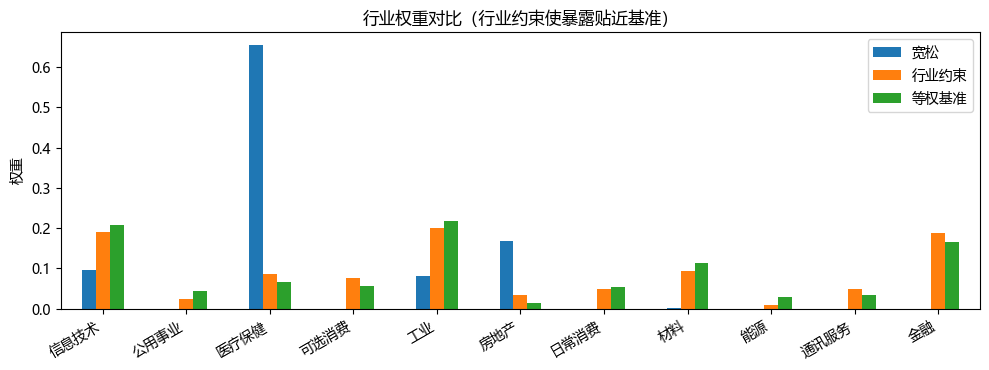

In [2]:
# 对比 宽松 与 单票+行业 的行业权重
def ind_weights(w):
    return pd.Series(w).groupby(industries).sum()
cmp_ind = pd.DataFrame({'宽松': ind_weights(W['宽松']),
                        '行业约束': ind_weights(W['单票5%+行业']),
                        '等权基准': ind_weights(eq)}).fillna(0)
cmp_ind.plot(kind='bar', figsize=(10, 3.8))
plt.title('行业权重对比（行业约束使暴露贴近基准）'); plt.ylabel('权重')
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

## 五、换手约束：控制交易成本

In [3]:
# 换手约束越紧，组合越接近上一期（等权）
for T in [0.1, 0.3, 0.6, 1.0]:
    w = optimize(alpha, Sigma, max_weight=0.05, w_prev=eq, max_turnover=T)
    print('换手上界 L1=%.1f  实际单边换手 %.3f  持仓 %d 只' %
          (T, turnover(w, eq), (w>1e-3).sum()))

换手上界 L1=0.1  实际单边换手 0.050  持仓 285 只


换手上界 L1=0.3  实际单边换手 0.150  持仓 255 只
换手上界 L1=0.6  实际单边换手 0.300  持仓 211 只


换手上界 L1=1.0  实际单边换手 0.500  持仓 152 只


## 六、指数增强：跟踪误差约束

指数增强（index enhancement）在**控制相对基准的跟踪误差**的前提下追求超额收益：
$$\max_w \alpha^\top w \quad \text{s.t.} \; \sqrt{(w-b)^\top\Sigma(w-b)} \le TE_{\max}$$
- $b$：基准权重；$TE$：跟踪误差（tracking error，相对基准的波动）；
- 组合在行业、风格上贴近基准，只在主动暴露上博取超额；
- 这是公募指数增强基金的标准范式（如 300 增强、500 增强）。

> 约束越严（TE 越小），越接近指数；越松，主动空间越大、偏离风险越大。

## 七、小结与面试要点

- 无约束优化极端不可投资；约束（单票、行业、风格、换手、跟踪误差）保证稳健可执行。
- 目标：max α^T w − λ/2 w^TΣw；约束都是凸的，cvxpy 求解。
- 指数增强：跟踪误差约束下最大化超额，贴近基准。

**面试高频：**
- 组合优化常见哪些约束？（答：单票、行业、风格、换手、跟踪误差）
- 什么是指数增强？跟踪误差？（答：控制相对基准偏离下追求超额；TE 是相对基准的波动）
- 换手约束怎么建模？（答：L1 范数 ‖w−w_prev‖₁ 上界）
- 约束多了会怎样？（答：牺牲理论最优，换稳健可执行）

## 动手练习
1. 加风格约束（限制小市值暴露），看组合收益变化；
2. 做指数增强：跟踪误差 2% vs 5%，对比预期超额；
3. 用因子模型协方差替代样本协方差，优化是否更稳定。

---
下一节 **5.5 风险指标与控制：波动率、回撤、Beta、VaR、集中度**。